# Benchmarking one bank's net charge-off rate against its DFAST peers

A worked example of a downstream use of [`bankqtr_db`](https://github.com/kiwi5boy/bankqtr_db).

<a id="executive-summary"></a>
## Executive summary

**Subject.** KeyCorp's net charge-off rates, benchmarked against 19 commercial-bank peers
screened out of the DFAST filer set. Position as at **2026Q2**. Source is the FFIEC Call
Report panel, cross-checked against the firm's own SEC filings (see
[section 1](#cross-checking-the-home-bank-against-the-other-source)).

**Bottom line.** The firm-wide loss rate is unremarkable against peers and has been for
years. It is concealing a commercial real estate book charging off at roughly **twice the
peer median**, ranking second of twenty, on a portfolio large enough to move the
firm-wide number on its own.

| Measure — trailing 4 quarters unless noted | KeyCorp | Peer median | Rank | Read |
|---|---|---|---|---|
| Whole book | 0.40% | 0.41% | 13 of 20 · 37th pct | In line |
| Whole book, 2026Q2 alone | 0.41% | 0.35% | 8 of 20 · 63rd pct | Quarterly noise — [§4](#has-the-position-moved) |
| C&I — 32.6% of loans | 0.50% | 0.46% | 10 of 20 · 53rd pct | In line |
| **CRE — 15.9% of loans** | **0.39%** | **0.22%** | **2 of 20 · 95th pct** | **Outlier — [§5](#the-outlier-test)** |
| Credit card — 0.9% of loans | 3.76% | 4.06% | 11 of 16 · 33rd pct | Below median, immaterial |

**What follows from it.**

1. **Do not escalate the headline move.** The jump to the 63rd percentile in 2026Q2 is one
   quarter of a series that has crossed the median in both directions repeatedly. The
   firm has sat inside the peer interquartile range in 45 of the 54 quarters since 2013 —
   and in four of the nine exceptions it was *below* the band.
2. **Take CRE to committee.** The questions are property type, vintage and office
   concentration inside that 0.39%, and whether the peers we sit above are simply slower
   to recognise the same problem.
3. **Pull the leading indicators next.** `nonaccrual_ratio_cre_nonfarm_nonres` and
   `dpd_30_89_pct_construction` are in the same panel. If those are also top-quartile,
   the trailing-four-quarter loss rate is a floor rather than a peak.

**Limitations.** Net charge-offs are a *lagging* measure — they record what has already
been written off, not what is about to be, so nothing here is a forecast. The peer group
is a reproducible screen ([section 2](#2-the-peer-group)), not a list the credit committee has
agreed. The FFIEC panel sums the firm's bank charters rather than consolidating the
holding company; for this firm the two sources differ by a median of 0.005 pp, but that
is a property of this firm, not a general guarantee.

> The figures in this summary and in [section 6](#6-what-a-risk-manager-would-actually-say) are the ones this notebook
> produced against the release current at 2026Q2. Prose has to commit to a number; the
> last cell of [section 5](#the-outlier-test) re-prints every one of them live, so a re-run
> against a later release shows at a glance whether this reading still stands.

<a id="contents"></a>
## Contents

- [Executive summary](#executive-summary)
- [Scope, question and sources](#scope-question-and-sources)
- [0. Parameters](#0-parameters)
- [1. Load and validate](#1-load-and-validate)
  - [Cross-checking the home bank against the other source](#cross-checking-the-home-bank-against-the-other-source)
- [2. The peer group](#2-the-peer-group)
- [3. Whole-book net charge-off rate through the cycle](#3-whole-book-net-charge-off-rate-through-the-cycle)
- [4. Where we sit in the latest quarter](#4-where-we-sit-in-the-latest-quarter)
  - [Has the position moved?](#has-the-position-moved)
- [5. Book-level breakdown](#5-book-level-breakdown)
  - [The outlier test](#the-outlier-test)
- [6. What a risk manager would actually say](#6-what-a-risk-manager-would-actually-say)
- [Where to go next](#where-to-go-next)

<a id="scope-question-and-sources"></a>
## Scope, question and sources

**The question.** A risk manager at a mid-sized regional wants to know three things
before the next credit committee:

1. Where does our net charge-off rate sit in the peer distribution?
2. Has that position moved, and over what horizon?
3. Is the whole-book number hiding an outlier in one particular book — C&I, CRE or card?

**The data.** Both panels are pulled straight from the latest release. The FFIEC panel
(`call_panel.parquet`) carries the analysis because it reaches back to 2001Q1, covers the
US intermediate holding companies of foreign banks that file no 10-K, and its loan
categories are a genuine partition of the RC-C schedule — so a book-level loss rate has a
denominator that means what it says. The EDGAR panel (`panel.parquet`) is used here as an
independent check on the home bank's headline number.

**What this notebook is not.** It is a benchmarking exercise, not a credit opinion. Net
charge-offs are a lagging indicator: they tell you what has already been written off, not
what is about to be. Nothing here is a forecast.

<a id="0-parameters"></a>
## 0. Parameters

Everything an analyst would want to change lives in this one cell. Swap `HOME_BANK` for
your own institution and re-run the notebook top to bottom.

In [1]:
# --- the subject -------------------------------------------------------------
# Any value in the panel's `bank` column. Run the cell in section 1 to see the list.
HOME_BANK = "KeyCorp"

# --- the peer group ----------------------------------------------------------
# The 38 firms in the FFIEC panel are the DFAST/CCAR filer universe, which is not a
# peer group: it mixes custody banks, broker-dealers, card monolines and regional
# commercial banks. Benchmarking a regional's loss rate against Synchrony's tells you
# nothing. This screen keeps firms whose balance sheet is shaped like a commercial
# bank's; loosen or tighten it, and section 2 will show you who moved in or out.
PEER_SCREEN = {
    "min_loans_to_assets": 35.0,   # % — drops custody banks and thin-loan-book dealers
    "max_credit_card_pct": 15.0,   # % of loans — drops the card monolines
    "min_ci_pct": 10.0,            # % of loans — requires a real commercial book
    "min_loans_total": 20e9,       # USD — drops firms too small to be comparable
}

# --- windows -----------------------------------------------------------------
HISTORY_START = "2001Q1"   # earliest quarter for the time series
N_RECENT_QUARTERS = 4      # book-level comparison window

# --- guards ------------------------------------------------------------------
# A loss rate on a near-empty book is arithmetic, not information. A firm is only
# counted in a book's distribution if that book is at least this share of its loans.
MIN_BOOK_SHARE_PCT = 0.25
# Annualised NCO rates outside this band are treated as data artefacts, not signal.
NCO_RATE_SANITY_PCT = 25.0
# Below this many peers a quarter's median and IQR are not worth plotting.
MIN_PEERS_PER_QUARTER = 8

In [2]:
import datetime as dt
import urllib.request
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import polars as pl
from matplotlib import font_manager

RELEASE = "https://github.com/kiwi5boy/bankqtr_db/releases/latest/download"
CACHE = Path("_data")


def fetch(name: str) -> Path:
    """Download a release asset once, then serve it from a local cache."""
    CACHE.mkdir(exist_ok=True)
    dest = CACHE / name
    if not dest.exists():
        print(f"downloading {name} ...")
        urllib.request.urlretrieve(f"{RELEASE}/{name}", dest)
    return dest


# --- chart styling -----------------------------------------------------------
# Two series carry meaning throughout: the home bank and the peer group. They keep the
# same colour in every chart, so a reader who learns "blue is us" never has to relearn it.
HOME_COLOR = "#2a78d6"
PEER_COLOR = "#eb6834"
INK = "#0b0b0b"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
SURFACE = "#fcfcfb"

# Resolve the UI sans against what is actually installed. Handing matplotlib a list of
# hopefuls makes it emit a `findfont: Font family 'X' not found` warning for every miss on
# every text object it draws - thousands of stderr lines saved into the notebook.
_installed = {f.name for f in font_manager.fontManager.ttflist}
FONT = next(
    (f for f in ("Segoe UI", "Helvetica Neue", "Inter", "Arial", "DejaVu Sans")
     if f in _installed),
    "sans-serif",
)

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "font.family": FONT,
    "font.size": 10,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": "#52514e",
    "axes.titlesize": 12,
    "axes.titleweight": "semibold",
    "axes.titlecolor": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "xtick.labelcolor": "#52514e",
    "ytick.labelcolor": "#52514e",
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "legend.frameon": False,
    "figure.dpi": 120,
})


def ordinal(n: float) -> str:
    """13 -> '13th', 63 -> '63rd'. Percentiles read badly without it."""
    i = round(n)
    suffix = "th" if 11 <= i % 100 <= 13 else {1: "st", 2: "nd", 3: "rd"}.get(i % 10, "th")
    return f"{i}{suffix}"


def tidy(ax, ylabel=None, pct=True):
    """Recessive horizontal grid, hairline axes, no chartjunk."""
    ax.grid(axis="y", zorder=0)
    ax.set_axisbelow(True)
    if ylabel:
        ax.set_ylabel(ylabel)
    if pct:
        ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f%%"))
    return ax

<a id="1-load-and-validate"></a>
## 1. Load and validate

Two files, straight from the latest GitHub release. They are cached in `_data/` so a
re-run costs nothing.

In [3]:
call = pl.read_parquet(fetch("call_panel.parquet"))   # FFIEC — charters summed to the firm
edgar = pl.read_parquet(fetch("panel.parquet"))       # SEC EDGAR — the holding company

for name, df in (("call_panel (FFIEC)", call), ("panel (EDGAR)", edgar)):
    print(
        f"{name:>20}: {df.height:>5,} rows x {df.width:>3} cols | "
        f"{df['quarter'].min()} - {df['quarter'].max()} | "
        f"{df['bank'].n_unique():>2} firms"
    )

downloading call_panel.parquet ...


downloading panel.parquet ...


  call_panel (FFIEC): 3,763 rows x 279 cols | 2001Q1 - 2026Q2 | 38 firms
       panel (EDGAR): 1,648 rows x 548 cols | 2013Q1 - 2026Q2 | 31 firms


In [4]:
# Who is in the FFIEC panel, and over what window. Coverage is not uniform: firms that
# were acquired stop, and firms that had no US charter early on start late.
coverage = (
    call.group_by("bank", "ticker")
    .agg(
        pl.col("quarter").min().alias("first"),
        pl.col("quarter").max().alias("last"),
        pl.len().alias("quarters"),
        pl.col("assets").last().alias("assets_last"),
    )
    .sort("assets_last", descending=True)
    .with_columns((pl.col("assets_last") / 1e9).round(1).alias("assets_bn"))
    .drop("assets_last")
)
with pl.Config(tbl_rows=50, tbl_width_chars=110):
    print(coverage)

shape: (38, 6)
┌───────────────────────────┬─────────┬────────┬────────┬──────────┬───────────┐
│ bank                      ┆ ticker  ┆ first  ┆ last   ┆ quarters ┆ assets_bn │
│ ---                       ┆ ---     ┆ ---    ┆ ---    ┆ ---      ┆ ---       │
│ str                       ┆ str     ┆ str    ┆ str    ┆ u32      ┆ f64       │
╞═══════════════════════════╪═════════╪════════╪════════╪══════════╪═══════════╡
│ JPMorgan Chase            ┆ JPM     ┆ 2001Q1 ┆ 2026Q2 ┆ 102      ┆ 4091.4    │
│ Bank of America           ┆ BAC     ┆ 2001Q1 ┆ 2026Q2 ┆ 102      ┆ 2669.5    │
│ Citigroup                 ┆ C       ┆ 2001Q1 ┆ 2026Q2 ┆ 102      ┆ 1976.2    │
│ Wells Fargo               ┆ WFC     ┆ 2001Q1 ┆ 2026Q2 ┆ 102      ┆ 1920.9    │
│ Goldman Sachs             ┆ GS      ┆ 2001Q4 ┆ 2026Q2 ┆ 99       ┆ 759.0     │
│ US Bancorp                ┆ USB     ┆ 2001Q1 ┆ 2026Q2 ┆ 102      ┆ 709.9     │
│ Morgan Stanley            ┆ MS      ┆ 2001Q1 ┆ 2026Q2 ┆ 102      ┆ 669.7     │
│ Capital One

In [5]:
assert HOME_BANK in set(call["bank"]), f"{HOME_BANK!r} is not in the panel - see the list above"

LATEST = call["period"].max()
LATEST_Q = call.filter(pl.col("period") == LATEST)["quarter"][0]
print(f"home bank      : {HOME_BANK}")
print(f"latest quarter : {LATEST_Q} ({LATEST})")
print(f"firms reporting: {call.filter(pl.col('period') == LATEST).height}")

# The accounting basis changed with CECL in 2020Q1. Charge-offs themselves are unaffected
# - CECL changed how reserves are set, not what a write-off is - but it is worth knowing
# which side of the line a quarter sits on.
print()
print(call.group_by("basis").agg(
    pl.col("quarter").min().alias("first"), pl.col("quarter").max().alias("last")
).sort("first"))

home bank      : KeyCorp
latest quarter : 2026Q2 (2026-06-30)
firms reporting: 35

shape: (2, 3)
┌──────────┬────────┬────────┐
│ basis    ┆ first  ┆ last   │
│ ---      ┆ ---    ┆ ---    │
│ str      ┆ str    ┆ str    │
╞══════════╪════════╪════════╡
│ incurred ┆ 2001Q1 ┆ 2019Q4 │
│ cecl     ┆ 2020Q1 ┆ 2026Q2 │
└──────────┴────────┴────────┘


In [6]:
# Sanity check the ratio before using it. `nco_rate` is annualised net charge-offs over
# total loans, in percent. A handful of firms hold a bank charter with an almost empty
# loan book, and a ratio with a near-zero denominator explodes.
absurd = (
    call.filter(pl.col("nco_rate").abs() > NCO_RATE_SANITY_PCT)
    .select("bank", "quarter", "nco_rate", "nco_total", "loans_total")
    .sort("nco_rate", descending=True)
)
print(f"rows with |nco_rate| > {NCO_RATE_SANITY_PCT}%: {absurd.height}")
print(absurd)
print()
print("nco_rate across the whole panel, ignoring those:")
print(call.filter(pl.col("nco_rate").abs() <= NCO_RATE_SANITY_PCT)["nco_rate"].describe())

rows with |nco_rate| > 25.0%: 2
shape: (2, 5)
┌────────────────┬─────────┬───────────┬───────────┬─────────────┐
│ bank           ┆ quarter ┆ nco_rate  ┆ nco_total ┆ loans_total │
│ ---            ┆ ---     ┆ ---       ┆ ---       ┆ ---         │
│ str            ┆ str     ┆ f64       ┆ f64       ┆ f64         │
╞════════════════╪═════════╪═══════════╪═══════════╪═════════════╡
│ Ameriprise     ┆ 2012Q3  ┆ 1.6441e6  ┆ 1.27414e8 ┆ 31000.0     │
│ Ally Financial ┆ 2009Q4  ┆ 29.136057 ┆ 1.8565e9  ┆ 2.5487e10   │
└────────────────┴─────────┴───────────┴───────────┴─────────────┘

nco_rate across the whole panel, ignoring those:
shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 3708.0    │
│ null_count ┆ 0.0       │
│ mean       ┆ 0.97464   │
│ std        ┆ 1.520357  │
│ min        ┆ -0.723547 │
│ 25%        ┆ 0.13757   │
│ 50%        ┆ 0.385338  │
│ 75%        ┆ 1.064573  │
│ m

The two rows above are exactly what the guard is for. Ameriprise 2012Q3 shows a
1,644,000% loss rate because its charter held USD 31 thousand of loans that quarter against
a charge-off booked elsewhere — arithmetic, not credit. Ally 2009Q4 at 29% is real: that is
the auto book in the trough of the crisis. The peer screen in the next section removes both
firms anyway, but a panel median computed without checking would have been silently wrong.

<a id="cross-checking-the-home-bank-against-the-other-source"></a>
### Cross-checking the home bank against the other source

The two panels are built from independent sources — FFIEC Call Reports summed across the
firm's bank charters, and the holding company's own SEC filings. They should agree on a
number as basic as the charge-off rate, and where they do not, the gap is itself
information (charge-offs booked outside an insured charter, mostly). This is a cheap
guard against building a benchmark on a broken series.

In [7]:
cross = (
    call.select("bank", "period", "quarter", pl.col("nco_rate").alias("ffiec"))
    .join(
        edgar.select(
            "bank",
            "period",
            pl.col("nco_rate").alias("edgar"),
            pl.col("nco_rate__source").alias("edgar_source"),
        ),
        on=["bank", "period"],
        how="inner",
    )
    .filter(pl.col("bank") == HOME_BANK)
    .with_columns((pl.col("ffiec") - pl.col("edgar")).abs().alias("abs_gap_pp"))
    .sort("period")
)
print(f"{HOME_BANK}: FFIEC vs EDGAR net charge-off rate, last 8 quarters")
print(cross.tail(8).select("quarter", "ffiec", "edgar", "abs_gap_pp", "edgar_source"))
print()
print(f"median absolute gap over {cross.height} overlapping quarters: "
      f"{cross['abs_gap_pp'].median():.4f} pp")

KeyCorp: FFIEC vs EDGAR net charge-off rate, last 8 quarters
shape: (8, 5)
┌─────────┬──────────┬──────────┬────────────┬──────────────┐
│ quarter ┆ ffiec    ┆ edgar    ┆ abs_gap_pp ┆ edgar_source │
│ ---     ┆ ---      ┆ ---      ┆ ---        ┆ ---          │
│ str     ┆ f64      ┆ f64      ┆ f64        ┆ str          │
╞═════════╪══════════╪══════════╪════════════╪══════════════╡
│ 2024Q3  ┆ 0.585923 ┆ 0.58474  ┆ 0.001183   ┆ xbrl         │
│ 2024Q4  ┆ 0.438895 ┆ 0.437368 ┆ 0.001527   ┆ xbrl         │
│ 2025Q1  ┆ 0.422234 ┆ 0.419811 ┆ 0.002422   ┆ xbrl         │
│ 2025Q2  ┆ 0.382686 ┆ 0.383498 ┆ 0.000812   ┆ xbrl         │
│ 2025Q3  ┆ 0.430845 ┆ 0.430587 ┆ 0.000258   ┆ xbrl         │
│ 2025Q4  ┆ 0.394696 ┆ 0.39046  ┆ 0.004236   ┆ xbrl         │
│ 2026Q1  ┆ 0.37287  ┆ 0.369997 ┆ 0.002873   ┆ xbrl         │
│ 2026Q2  ┆ 0.413184 ┆ 0.416553 ┆ 0.00337    ┆ xbrl         │
└─────────┴──────────┴──────────┴────────────┴──────────────┘

median absolute gap over 54 overlapping quarters: 0.0048

<a id="2-the-peer-group"></a>
## 2. The peer group

The DFAST filer universe is a regulatory perimeter, not a comparable set. Applying the
screen from section 0 quarter by quarter — rather than fixing membership at the latest
quarter and back-filling it — keeps the comparison honest through acquisitions and
exits, at the cost of a peer count that moves. The chart in section 3 shows that count so
composition changes are visible rather than hidden.

The home bank is always the subject, whether or not it passes the screen. Peer medians and
quartiles are computed **excluding** the home bank, so the benchmark is not partly a
reflection of the bank being benchmarked.

In [8]:
screen = (
    (pl.col("loans_to_assets") >= PEER_SCREEN["min_loans_to_assets"])
    & (pl.col("credit_card_pct") <= PEER_SCREEN["max_credit_card_pct"])
    & (pl.col("ci_pct") >= PEER_SCREEN["min_ci_pct"])
    & (pl.col("loans_total") >= PEER_SCREEN["min_loans_total"])
).fill_null(False)

panel = (
    call.filter(
        (pl.col("quarter") >= HISTORY_START)
        & (pl.col("nco_rate").abs() <= NCO_RATE_SANITY_PCT)
    )
    .with_columns(
        screen.alias("passes_screen"),
        (pl.col("bank") == HOME_BANK).alias("is_home"),
    )
    .with_columns(
        (pl.col("passes_screen") & ~pl.col("is_home")).alias("is_peer"),
        (pl.col("passes_screen") | pl.col("is_home")).alias("in_cohort"),
    )
)

home_passes = panel.filter(pl.col("is_home") & (pl.col("period") == LATEST))["passes_screen"]
print(f"{HOME_BANK} passes its own peer screen in {LATEST_Q}: {bool(home_passes[0])}")

KeyCorp passes its own peer screen in 2026Q2: True


In [9]:
latest = panel.filter(pl.col("period") == LATEST)
cols = ["bank", "loans_to_assets", "credit_card_pct", "ci_pct", "loans_total"]


def fmt(d: pl.DataFrame) -> pl.DataFrame:
    return (
        d.select(cols)
        .with_columns(pl.col("loans_total").truediv(1e9).round(1).alias("loans_bn"))
        .drop("loans_total")
        .sort("loans_bn", descending=True)
    )


print(f"IN the peer group ({latest.filter(pl.col('is_peer')).height} firms):")
with pl.Config(tbl_rows=40, tbl_width_chars=110):
    print(fmt(latest.filter(pl.col("is_peer"))))
    print()
    print(f"SCREENED OUT ({latest.filter(~pl.col('passes_screen')).height} firms):")
    print(fmt(latest.filter(~pl.col("passes_screen"))))

IN the peer group (19 firms):
shape: (19, 5)
┌───────────────────────────┬─────────────────┬─────────────────┬───────────┬──────────┐
│ bank                      ┆ loans_to_assets ┆ credit_card_pct ┆ ci_pct    ┆ loans_bn │
│ ---                       ┆ ---             ┆ ---             ┆ ---       ┆ ---      │
│ str                       ┆ f64             ┆ f64             ┆ f64       ┆ f64      │
╞═══════════════════════════╪═════════════════╪═════════════════╪═══════════╪══════════╡
│ JPMorgan Chase            ┆ 37.150707       ┆ 14.222039       ┆ 15.911272 ┆ 1520.0   │
│ Bank of America           ┆ 45.495024       ┆ 8.700002        ┆ 26.633242 ┆ 1214.5   │
│ Wells Fargo               ┆ 52.135252       ┆ 5.830973        ┆ 19.995701 ┆ 1001.4   │
│ US Bancorp                ┆ 57.796682       ┆ 8.029932        ┆ 22.396559 ┆ 410.3    │
│ PNC Financial             ┆ 60.348964       ┆ 1.718326        ┆ 31.67303  ┆ 368.0    │
│ Truist Financial          ┆ 60.160373       ┆ 0.972151        ┆

<a id="3-whole-book-net-charge-off-rate-through-the-cycle"></a>
## 3. Whole-book net charge-off rate through the cycle

The home bank against the peer median, with the interquartile range shaded. The band is
the thing to read: a line inside it is unremarkable however it moves, and a line that
leaves it is worth explaining.

In [10]:
peer_ts = (
    panel.filter(pl.col("is_peer"))
    .group_by("period")
    .agg(
        pl.col("nco_rate").median().alias("p50"),
        pl.col("nco_rate").quantile(0.25, interpolation="linear").alias("p25"),
        pl.col("nco_rate").quantile(0.75, interpolation="linear").alias("p75"),
        pl.col("nco_rate").drop_nulls().len().alias("n_peers"),
    )
    .filter(pl.col("n_peers") >= MIN_PEERS_PER_QUARTER)
    .sort("period")
)
home_ts = (
    panel.filter(pl.col("is_home"))
    .select("period", "quarter", "nco_rate")
    .drop_nulls("nco_rate")
    .sort("period")
)
print(f"peer count ranges {peer_ts['n_peers'].min()} - {peer_ts['n_peers'].max()} "
      f"over {peer_ts.height} quarters")
print(peer_ts.tail(4))

peer count ranges 16 - 25 over 102 quarters
shape: (4, 5)
┌────────────┬──────────┬──────────┬──────────┬─────────┐
│ period     ┆ p50      ┆ p25      ┆ p75      ┆ n_peers │
│ ---        ┆ ---      ┆ ---      ┆ ---      ┆ ---     │
│ date       ┆ f64      ┆ f64      ┆ f64      ┆ u32     │
╞════════════╪══════════╪══════════╪══════════╪═════════╡
│ 2025-09-30 ┆ 0.472272 ┆ 0.336218 ┆ 0.668355 ┆ 20      │
│ 2025-12-31 ┆ 0.434529 ┆ 0.219365 ┆ 0.582989 ┆ 19      │
│ 2026-03-31 ┆ 0.383987 ┆ 0.233432 ┆ 0.571517 ┆ 19      │
│ 2026-06-30 ┆ 0.349925 ┆ 0.234678 ┆ 0.48336  ┆ 19      │
└────────────┴──────────┴──────────┴──────────┴─────────┘


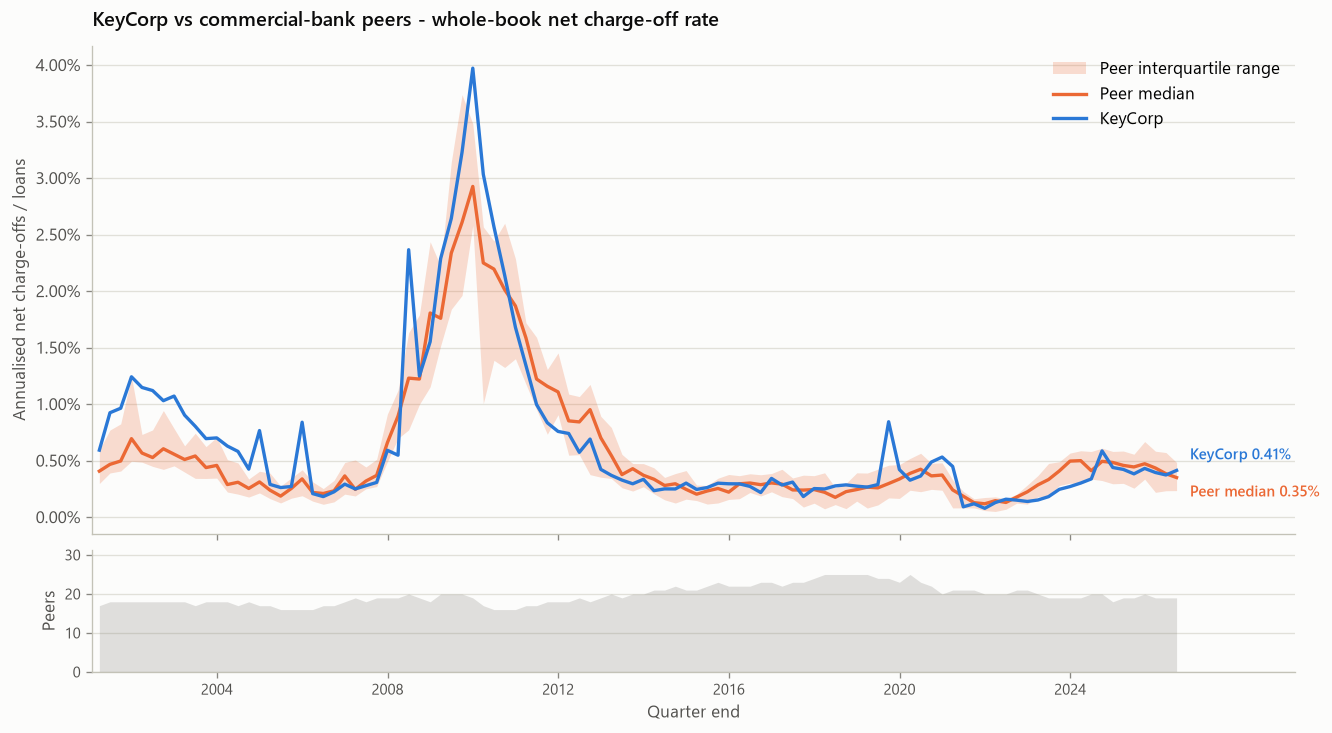

In [11]:
fig, (ax, ax_n) = plt.subplots(
    2, 1, figsize=(11, 6), sharex=True, height_ratios=[4, 1], constrained_layout=True
)

x = peer_ts["period"].to_list()
ax.fill_between(
    x, peer_ts["p25"], peer_ts["p75"],
    color=PEER_COLOR, alpha=0.22, linewidth=0, zorder=1,
    label="Peer interquartile range",
)
ax.plot(x, peer_ts["p50"], color=PEER_COLOR, linewidth=2, zorder=2, label="Peer median")
ax.plot(
    home_ts["period"].to_list(), home_ts["nco_rate"],
    color=HOME_COLOR, linewidth=2, zorder=3, label=HOME_BANK,
)

# Direct-label the two lines at the right edge instead of relying on the legend alone.
# The two end points sit within a few basis points of each other, so the labels are
# nudged apart vertically rather than allowed to overprint.
for series, colour, label, dy in (
    (home_ts.select("period", pl.col("nco_rate").alias("v")), HOME_COLOR, HOME_BANK, 9),
    (peer_ts.select("period", pl.col("p50").alias("v")), PEER_COLOR, "Peer median", -9),
):
    last = series.sort("period").tail(1)
    ax.annotate(
        f"{label} {last['v'][0]:.2f}%",
        xy=(last["period"][0], last["v"][0]),
        xytext=(8, dy), textcoords="offset points",
        color=colour, fontsize=9, fontweight="semibold", va="center",
    )

tidy(ax, ylabel="Annualised net charge-offs / loans")
ax.set_title(
    f"{HOME_BANK} vs commercial-bank peers - whole-book net charge-off rate",
    loc="left", pad=12,
)
ax.legend(loc="upper right", ncols=1)

# Reserve room on the right for the end labels so nothing overflows the axes.
span_days = (x[-1] - x[0]).days
ax.set_xlim(x[0] - dt.timedelta(days=60), x[-1] + dt.timedelta(days=int(span_days * 0.11)))

ax_n.fill_between(x, 0, peer_ts["n_peers"], color=INK_MUTED, alpha=0.25, linewidth=0)
tidy(ax_n, ylabel="Peers", pct=False)
ax_n.set_ylim(0, peer_ts["n_peers"].max() * 1.25)
ax_n.set_xlabel("Quarter end")
ax_n.tick_params(labelsize=9)
# The right-hand padding is there for the labels, not for data - so no tick may imply
# a quarter that does not exist. Fixing the ticks drops the automatic date formatter,
# so it has to be put back.
lo, _ = ax_n.get_xlim()
last_num = mdates.date2num(x[-1])
ax_n.set_xticks([t for t in ax_n.get_xticks() if lo <= t <= last_num])
ax_n.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

The lower strip is the peer count behind each quarter's median. It matters: a band drawn
from 16 firms and a band drawn from 25 are not the same object, and steps in that count
line up with acquisitions rather than with anything about credit.

<a id="4-where-we-sit-in-the-latest-quarter"></a>
## 4. Where we sit in the latest quarter

Rank and percentile, on the convention that **higher is worse** — the 90th percentile
means nine tenths of the cohort charged off less than we did. The cohort here is the peer
group plus the home bank, since a rank has to include the thing being ranked.

In [12]:
def percentile_of(values: list[float], value: float) -> float:
    """Share of the cohort strictly below `value`, in percent. Higher = worse."""
    others = [v for v in values if v is not None]
    return 100.0 * sum(1 for v in others if v < value) / (len(others) - 1)


cohort = (
    panel.filter((pl.col("period") == LATEST) & pl.col("in_cohort"))
    .select("bank", "nco_rate", "is_home", "loans_total")
    .drop_nulls("nco_rate")
    .sort("nco_rate", descending=True)
)
values = cohort["nco_rate"].to_list()
home_rate = cohort.filter(pl.col("is_home"))["nco_rate"][0]
home_rank = sum(1 for v in values if v > home_rate) + 1
home_pctile = percentile_of(values, home_rate)
peer_median = panel.filter((pl.col("period") == LATEST) & pl.col("is_peer"))["nco_rate"].median()

print(f"{LATEST_Q}: {HOME_BANK} net charge-off rate {home_rate:.3f}%")
print(f"        peer median {peer_median:.3f}%  ({home_rate - peer_median:+.3f} pp)")
print(f"        rank {home_rank} of {len(values)} (1 = highest loss rate)")
print(f"        {ordinal(home_pctile)} percentile")

2026Q2: KeyCorp net charge-off rate 0.413%
        peer median 0.350%  (+0.063 pp)
        rank 8 of 20 (1 = highest loss rate)
        63rd percentile


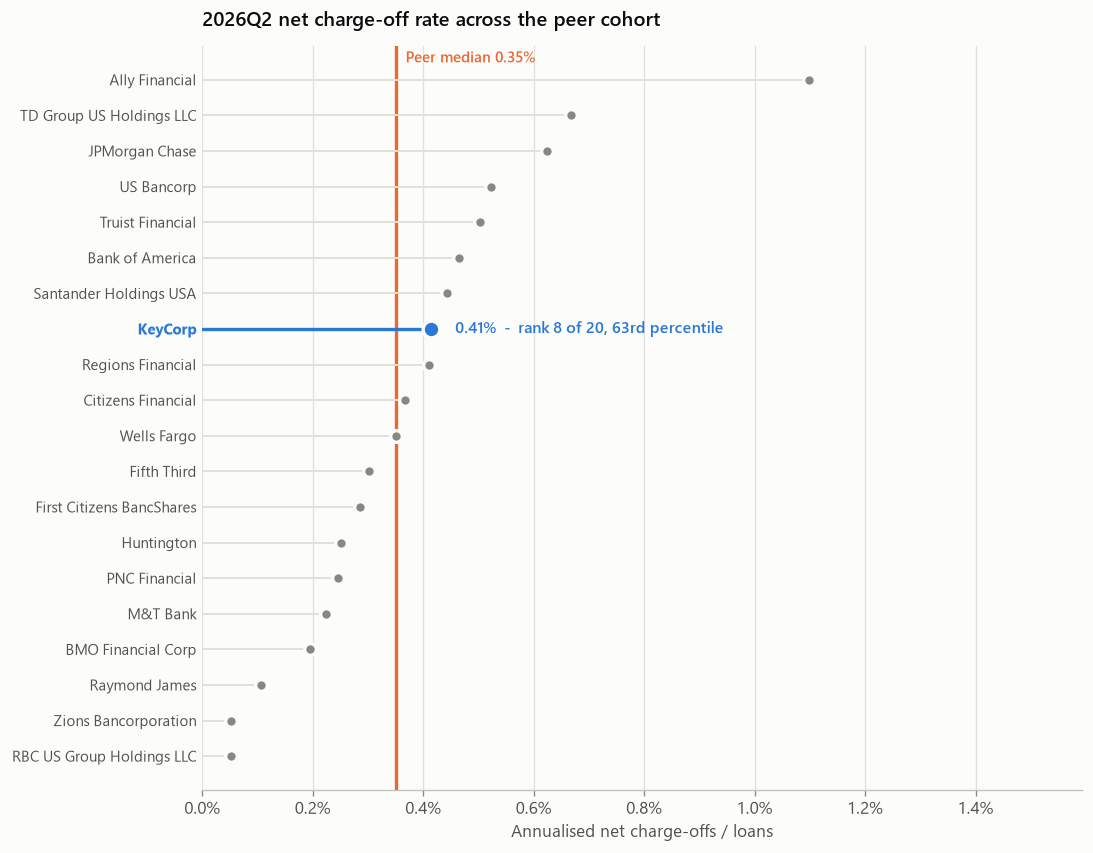

In [13]:
fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)

order = cohort.sort("nco_rate")            # lowest at the bottom
ys = range(order.height)
rates = order["nco_rate"].to_list()
names = order["bank"].to_list()
is_home = order["is_home"].to_list()

ax.axvline(peer_median, color=PEER_COLOR, linewidth=2, zorder=2)
ax.annotate(
    f"Peer median {peer_median:.2f}%",
    xy=(peer_median, order.height - 0.4), xytext=(6, 0), textcoords="offset points",
    color=PEER_COLOR, fontsize=9, fontweight="semibold", va="center",
)

for y, rate, home in zip(ys, rates, is_home):
    ax.plot(
        [0, rate], [y, y],
        color=HOME_COLOR if home else GRID,
        linewidth=2 if home else 1.2, zorder=3, solid_capstyle="round",
    )
    ax.plot(
        rate, y, "o",
        color=HOME_COLOR if home else INK_MUTED,
        markersize=10 if home else 7,
        markeredgecolor=SURFACE, markeredgewidth=2, zorder=4,
    )

ax.set_yticks(list(ys))
ax.set_yticklabels(names, fontsize=9)
for tick, home in zip(ax.get_yticklabels(), is_home):
    if home:
        tick.set_color(HOME_COLOR)
        tick.set_fontweight("bold")

# Only the subject gets a value label; the axis carries the rest.
home_y = is_home.index(True)
ax.annotate(
    f"  {home_rate:.2f}%  -  rank {home_rank} of {len(values)}, {ordinal(home_pctile)} percentile",
    xy=(home_rate, home_y), xytext=(10, 0), textcoords="offset points",
    color=HOME_COLOR, fontsize=9.5, fontweight="semibold", va="center",
)

ax.grid(axis="x", zorder=0)
ax.set_axisbelow(True)
ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%.1f%%"))
ax.set_xlabel("Annualised net charge-offs / loans")
ax.set_xlim(min(0, min(rates) * 1.15), max(rates) * 1.45)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title(f"{LATEST_Q} net charge-off rate across the peer cohort", loc="left", pad=12)
plt.show()

<a id="has-the-position-moved"></a>
### Has the position moved?

A single quarter's rank is noisy — one lumpy commercial credit moves a mid-sized bank
several places. Tracking the percentile through time separates a drift from a blip.

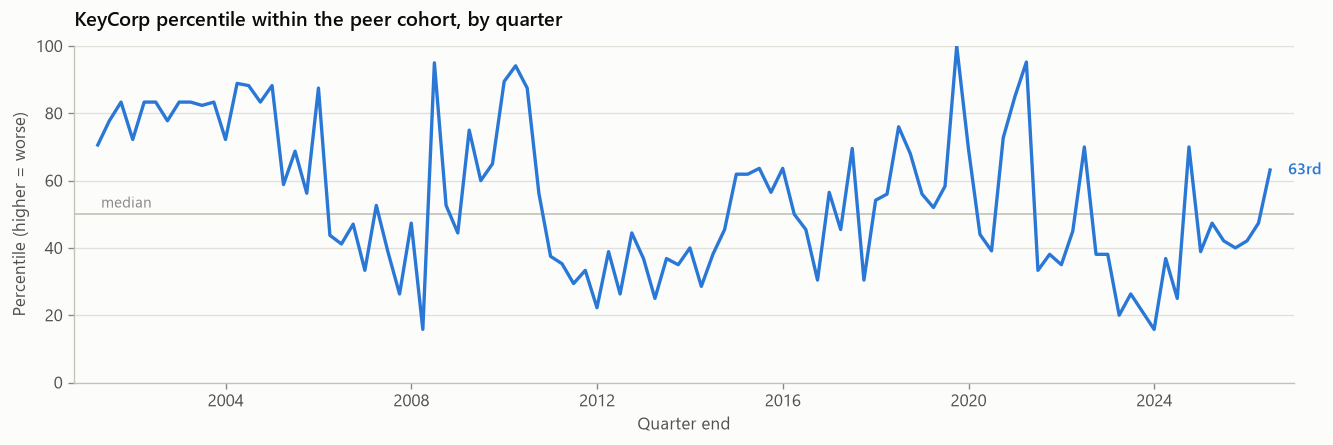

last eight quarters:
shape: (8, 3)
┌────────────┬────────┬─────┐
│ period     ┆ pctile ┆ n   │
│ ---        ┆ ---    ┆ --- │
│ date       ┆ f64    ┆ i64 │
╞════════════╪════════╪═════╡
│ 2024-09-30 ┆ 70.0   ┆ 21  │
│ 2024-12-31 ┆ 39.0   ┆ 19  │
│ 2025-03-31 ┆ 47.0   ┆ 20  │
│ 2025-06-30 ┆ 42.0   ┆ 20  │
│ 2025-09-30 ┆ 40.0   ┆ 21  │
│ 2025-12-31 ┆ 42.0   ┆ 20  │
│ 2026-03-31 ┆ 47.0   ┆ 20  │
│ 2026-06-30 ┆ 63.0   ┆ 20  │
└────────────┴────────┴─────┘


In [14]:
rank_rows = []
for (period,), grp in panel.filter(pl.col("in_cohort")).group_by(["period"], maintain_order=False):
    vals = grp["nco_rate"].drop_nulls().to_list()
    home = grp.filter(pl.col("is_home"))["nco_rate"].drop_nulls().to_list()
    if not home or len(vals) < MIN_PEERS_PER_QUARTER:
        continue
    rank_rows.append({
        "period": period,
        "pctile": percentile_of(vals, home[0]),
        "n": len(vals),
    })
ranks = pl.DataFrame(rank_rows).sort("period")

fig, ax = plt.subplots(figsize=(11, 3.6), constrained_layout=True)
ax.axhline(50, color=AXIS, linewidth=1)
ax.annotate("median", xy=(ranks["period"].min(), 50), xytext=(2, 4),
            textcoords="offset points", color=INK_MUTED, fontsize=9)
ax.plot(ranks["period"].to_list(), ranks["pctile"], color=HOME_COLOR, linewidth=2)
last = ranks.tail(1)
ax.annotate(
    f"  {ordinal(last['pctile'][0])}",
    xy=(last["period"][0], last["pctile"][0]), xytext=(6, 0), textcoords="offset points",
    color=HOME_COLOR, fontsize=9.5, fontweight="semibold", va="center",
)
tidy(ax, ylabel="Percentile (higher = worse)", pct=False)
ax.set_ylim(0, 100)
ax.margins(x=0.02)
ax.set_xlabel("Quarter end")
ax.set_title(f"{HOME_BANK} percentile within the peer cohort, by quarter", loc="left", pad=12)
plt.show()

print("last eight quarters:")
print(ranks.tail(8).with_columns(pl.col("pctile").round(0)))

<a id="5-book-level-breakdown"></a>
## 5. Book-level breakdown

A whole-book rate is a weighted average, and averages hide things. The three books below
are where a regional's losses actually come from, and each is compared against the peer
median **for that book** — computed only over peers that actually run one, using the
`MIN_BOOK_SHARE_PCT` guard from section 0. Without that guard the card median would be
dragged around by banks holding a token card portfolio.

Note the panels do not share a y-scale. Card loss rates run an order of magnitude above
commercial ones; forcing them onto one axis would flatten C&I and CRE into nothing.

In [15]:
BOOKS = [
    ("C&I", "nco_rate_ci", "nco_ci", "loans_ci"),
    ("CRE", "nco_rate_cre", "nco_cre_total", "loans_cre_total"),
    ("Credit card", "nco_rate_card", "nco_credit_card", "loans_credit_card"),
]
recent_q = sorted(panel["quarter"].unique().to_list())[-N_RECENT_QUARTERS:]
print("window:", ", ".join(recent_q))

recent = panel.filter(pl.col("quarter").is_in(recent_q))


def book_frame(rate_col: str, bal_col: str) -> pl.DataFrame:
    """Home rate, peer median and book share per quarter, materiality-screened."""
    share = pl.col(bal_col) / pl.col("loans_total") * 100
    material = (share >= MIN_BOOK_SHARE_PCT).fill_null(False)
    peers = (
        recent.filter(pl.col("is_peer") & material)
        .group_by("quarter")
        .agg(
            pl.col(rate_col).median().alias("peer_p50"),
            pl.col(rate_col).drop_nulls().len().alias("n_peers"),
        )
    )
    home = recent.filter(pl.col("is_home")).select(
        "quarter",
        pl.col(rate_col).alias("home"),
        share.alias("home_share_pct"),
    )
    return home.join(peers, on="quarter", how="left").sort("quarter")


book_frames = {label: book_frame(rate, bal) for label, rate, _, bal in BOOKS}
for label, frame in book_frames.items():
    print()
    print(label)
    print(frame)

window: 2025Q3, 2025Q4, 2026Q1, 2026Q2

C&I
shape: (4, 5)
┌─────────┬───────────┬────────────────┬──────────┬─────────┐
│ quarter ┆ home      ┆ home_share_pct ┆ peer_p50 ┆ n_peers │
│ ---     ┆ ---       ┆ ---            ┆ ---      ┆ ---     │
│ str     ┆ f64       ┆ f64            ┆ f64      ┆ u32     │
╞═════════╪═══════════╪════════════════╪══════════╪═════════╡
│ 2025Q3  ┆ 0.865656  ┆ 32.031635      ┆ 0.532673 ┆ 20      │
│ 2025Q4  ┆ -0.225606 ┆ 32.510039      ┆ 0.34571  ┆ 19      │
│ 2026Q1  ┆ 0.785652  ┆ 32.232645      ┆ 0.371397 ┆ 19      │
│ 2026Q2  ┆ 0.560658  ┆ 33.789203      ┆ 0.416753 ┆ 19      │
└─────────┴───────────┴────────────────┴──────────┴─────────┘

CRE
shape: (4, 5)
┌─────────┬──────────┬────────────────┬──────────┬─────────┐
│ quarter ┆ home     ┆ home_share_pct ┆ peer_p50 ┆ n_peers │
│ ---     ┆ ---      ┆ ---            ┆ ---      ┆ ---     │
│ str     ┆ f64      ┆ f64            ┆ f64      ┆ u32     │
╞═════════╪══════════╪════════════════╪══════════╪═════════

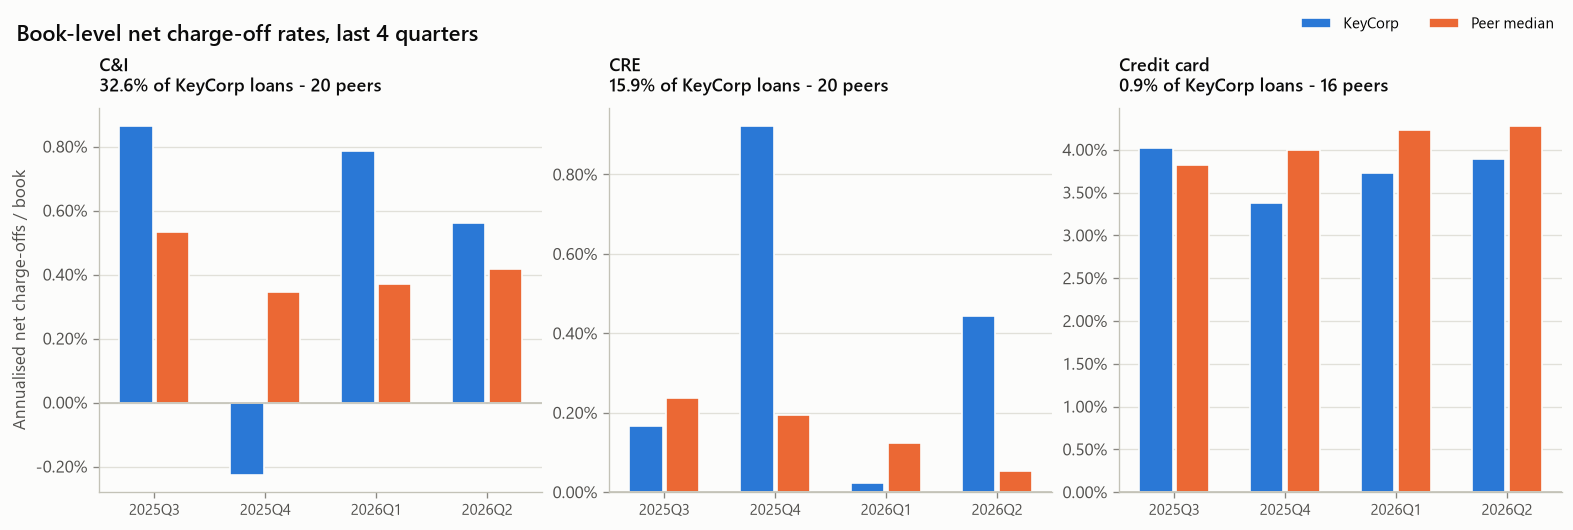

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), constrained_layout=True)
width, gap = 0.30, 0.015     # thin marks, with a surface-width gap between the pair

for ax, (label, _rate, _num, _bal) in zip(axes, BOOKS):
    frame = book_frames[label]
    xs = range(frame.height)
    ax.bar(
        [i - width / 2 - gap for i in xs], frame["home"], width,
        color=HOME_COLOR, zorder=3, label=HOME_BANK,
        edgecolor=SURFACE, linewidth=1,
    )
    ax.bar(
        [i + width / 2 + gap for i in xs], frame["peer_p50"], width,
        color=PEER_COLOR, zorder=3, label="Peer median",
        edgecolor=SURFACE, linewidth=1,
    )
    ax.axhline(0, color=AXIS, linewidth=1, zorder=4)
    ax.set_xticks(list(xs))
    ax.set_xticklabels(frame["quarter"], fontsize=9)
    tidy(ax, pct=True)
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f%%"))
    share = frame["home_share_pct"].mean()
    n_peers = int(frame["n_peers"].max())
    ax.set_title(
        f"{label}\n{share:.1f}% of {HOME_BANK} loans - {n_peers} peers",
        loc="left", pad=10, fontsize=11,
    )

axes[0].set_ylabel("Annualised net charge-offs / book")
fig.suptitle(
    f"Book-level net charge-off rates, last {N_RECENT_QUARTERS} quarters",
    x=0.006, ha="left", fontsize=13, fontweight="semibold", color=INK,
)
# One legend for all three panels, out of the plotting area.
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncols=2, fontsize=9,
           bbox_to_anchor=(1.0, 1.03))
plt.show()

<a id="the-outlier-test"></a>
### The outlier test

Quarterly book-level rates are too lumpy to rank on — one CRE workout can swing a quarter.
Pooling four quarters of charge-off dollars over the average book balance gives a rate
stable enough to compare, and that is what the table below ranks. This is the cell that
answers *"are we an outlier on any specific book?"*

In [17]:
def trailing_rank(num_col: str, bal_col: str) -> dict:
    g = (
        recent.filter(pl.col("in_cohort"))
        .group_by("bank")
        .agg(
            pl.col(num_col).sum().alias("nco_sum"),
            pl.col(bal_col).mean().alias("bal_avg"),
            pl.col(bal_col).count().alias("n_q"),
            pl.col("loans_total").mean().alias("loans_avg"),
            pl.col("is_home").any().alias("is_home"),
        )
        .filter(pl.col("n_q") == len(recent_q))
        .with_columns(
            (pl.col("nco_sum") / pl.col("bal_avg") * 100).alias("rate"),
            (pl.col("bal_avg") / pl.col("loans_avg") * 100).alias("share"),
        )
        .filter((pl.col("share") >= MIN_BOOK_SHARE_PCT) & pl.col("rate").is_not_null())
        .sort("rate", descending=True)
    )
    vals = g["rate"].to_list()
    home = g.filter(pl.col("is_home"))
    if home.is_empty():
        return {}
    rate = home["rate"][0]
    return {
        "n": len(vals),
        "home_rate": rate,
        "home_share": home["share"][0],
        "peer_median": g.filter(~pl.col("is_home"))["rate"].median(),
        "rank": sum(1 for v in vals if v > rate) + 1,
        "pctile": percentile_of(vals, rate),
        "table": g,
    }


summary = pl.DataFrame([
    {
        "book": label,
        "home_rate_pct": r["home_rate"],
        "peer_median_pct": r["peer_median"],
        "gap_pp": r["home_rate"] - r["peer_median"],
        "book_share_pct": r["home_share"],
        "rank": r["rank"],
        "of": r["n"],
        "pctile": r["pctile"],
    }
    for label, r in (
        (label, trailing_rank(num, bal))
        for label, _rate, num, bal in
        [("Total loans", "nco_rate", "nco_total", "loans_total")] + BOOKS
    )
    if r
]).with_columns(pl.col(pl.Float64).round(2))

print(f"Trailing {N_RECENT_QUARTERS} quarters ({recent_q[0]} - {recent_q[-1]}), "
      f"charge-off dollars over average book balance")
with pl.Config(tbl_width_chars=120):
    print(summary)

Trailing 4 quarters (2025Q3 - 2026Q2), charge-off dollars over average book balance
shape: (4, 8)
┌─────────────┬───────────────┬─────────────────┬────────┬────────────────┬──────┬─────┬────────┐
│ book        ┆ home_rate_pct ┆ peer_median_pct ┆ gap_pp ┆ book_share_pct ┆ rank ┆ of  ┆ pctile │
│ ---         ┆ ---           ┆ ---             ┆ ---    ┆ ---            ┆ ---  ┆ --- ┆ ---    │
│ str         ┆ f64           ┆ f64             ┆ f64    ┆ f64            ┆ i64  ┆ i64 ┆ f64    │
╞═════════════╪═══════════════╪═════════════════╪════════╪════════════════╪══════╪═════╪════════╡
│ Total loans ┆ 0.4           ┆ 0.41            ┆ -0.01  ┆ 100.0          ┆ 13   ┆ 20  ┆ 36.84  │
│ C&I         ┆ 0.5           ┆ 0.46            ┆ 0.04   ┆ 32.65          ┆ 10   ┆ 20  ┆ 52.63  │
│ CRE         ┆ 0.39          ┆ 0.22            ┆ 0.17   ┆ 15.87          ┆ 2    ┆ 20  ┆ 94.74  │
│ Credit card ┆ 3.76          ┆ 4.06            ┆ -0.31  ┆ 0.86           ┆ 11   ┆ 16  ┆ 33.33  │
└─────────────┴─────

In [18]:
# The one book the summary flags, shown in full so the ranking can be checked by eye.
worst = summary.sort("pctile", descending=True).row(0, named=True)
label = worst["book"]
_, _, num, bal = next(b for b in
                      [("Total loans", "nco_rate", "nco_total", "loans_total")] + BOOKS
                      if b[0] == label)
detail = trailing_rank(num, bal)["table"]
print(f"{label}: trailing-{N_RECENT_QUARTERS}Q net charge-off rate, full cohort")
with pl.Config(tbl_rows=30, tbl_width_chars=100):
    print(
        detail.select(
            "bank",
            pl.col("rate").round(3).alias("nco_rate_pct"),
            pl.col("share").round(1).alias("book_share_pct"),
            "is_home",
        )
    )

CRE: trailing-4Q net charge-off rate, full cohort
shape: (20, 4)
┌───────────────────────────┬──────────────┬────────────────┬─────────┐
│ bank                      ┆ nco_rate_pct ┆ book_share_pct ┆ is_home │
│ ---                       ┆ ---          ┆ ---            ┆ ---     │
│ str                       ┆ f64          ┆ f64            ┆ bool    │
╞═══════════════════════════╪══════════════╪════════════════╪═════════╡
│ Citizens Financial        ┆ 0.567        ┆ 19.1           ┆ false   │
│ KeyCorp                   ┆ 0.388        ┆ 15.9           ┆ true    │
│ Raymond James             ┆ 0.311        ┆ 15.3           ┆ false   │
│ First Citizens BancShares ┆ 0.28         ┆ 26.2           ┆ false   │
│ Bank of America           ┆ 0.27         ┆ 6.9            ┆ false   │
│ Santander Holdings USA    ┆ 0.266        ┆ 32.9           ┆ false   │
│ Wells Fargo               ┆ 0.255        ┆ 13.1           ┆ false   │
│ Regions Financial         ┆ 0.231        ┆ 16.0           ┆ false   │

In [19]:
# A live one-line read of every figure the interpretation below leans on, so a re-run
# against a newer release shows immediately whether the narrative still holds.
tot = summary.filter(pl.col("book") == "Total loans").row(0, named=True)
print(f"AS OF {LATEST_Q} | home bank: {HOME_BANK} | peers: {latest.filter(pl.col('is_peer')).height}")
print(f"  latest quarter    {home_rate:.2f}% vs peer median {peer_median:.2f}% "
      f"-> {ordinal(home_pctile)} percentile (rank {home_rank} of {len(values)})")
print(f"  trailing {N_RECENT_QUARTERS}Q total  {tot['home_rate_pct']:.2f}% vs {tot['peer_median_pct']:.2f}% "
      f"-> {ordinal(tot['pctile'])} percentile")
for row in summary.filter(pl.col("book") != "Total loans").iter_rows(named=True):
    print(f"  trailing {N_RECENT_QUARTERS}Q {row['book']:<12} {row['home_rate_pct']:.2f}% "
          f"vs {row['peer_median_pct']:.2f}% -> {ordinal(row['pctile'])} percentile "
          f"(book is {row['book_share_pct']:.1f}% of loans)")

# How often the home bank has actually left the interquartile band. 2013Q1 is the cut
# because that is where the EDGAR panel starts, so it is the window both sources cover.
band = home_ts.join(peer_ts, on="period", how="inner").filter(pl.col("quarter") >= "2013Q1")
above = band.filter(pl.col("nco_rate") > pl.col("p75")).height
below = band.filter(pl.col("nco_rate") < pl.col("p25")).height
print(f"  since 2013Q1      inside the peer IQR in {band.height - above - below} of "
      f"{band.height} quarters ({above} above, {below} below)")

AS OF 2026Q2 | home bank: KeyCorp | peers: 19
  latest quarter    0.41% vs peer median 0.35% -> 63rd percentile (rank 8 of 20)
  trailing 4Q total  0.40% vs 0.41% -> 37th percentile
  trailing 4Q C&I          0.50% vs 0.46% -> 53rd percentile (book is 32.6% of loans)
  trailing 4Q CRE          0.39% vs 0.22% -> 95th percentile (book is 15.9% of loans)
  trailing 4Q Credit card  3.76% vs 4.06% -> 33rd percentile (book is 0.9% of loans)
  since 2013Q1      inside the peer IQR in 45 of 54 quarters (5 above, 4 below)


<a id="6-what-a-risk-manager-would-actually-say"></a>
## 6. What a risk manager would actually say

> Figures below are pinned to the 2026Q2 release, for the reason given in the
> [executive summary](#executive-summary); the cell directly above re-prints them live.

On the headline number we are unremarkable and should say so plainly: our whole-book net
charge-off rate ran 0.40% over the last four quarters against a peer median of 0.41%,
which puts us thirteenth of twenty — comfortably inside the interquartile band, where we
have sat in forty-five of the fifty-four quarters since 2013, and in four of the nine
exceptions we were below the band rather than above it. The single-quarter figure for 2026Q2 is
0.41% against a peer median of 0.35%, which lifts us to the 63rd percentile from the low
40s in the preceding three quarters. That move is one quarter of a noisy series, not a
trend, and the percentile chart makes the case: we have crossed the median in both
directions repeatedly without anything changing underneath. It is not something to take to
committee as a deterioration. What *is* worth taking to committee is that the average is
concealing a genuine outlier. Our commercial real estate book charged off 0.39%
annualised over the trailing four quarters against a peer median of 0.22% — the second
highest rate in a twenty-firm cohort, the 95th percentile — on a book that is 16% of total
loans, so it is material enough to move the firm-wide number on its own. C&I is
unexceptional at 0.50% against a 0.46% median (53rd percentile), and card, where we sit
below the median at 3.76% against 4.06%, is 0.9% of loans and therefore not worth the
meeting time either way. The honest summary is: one book, not the balance sheet. The
follow-up questions are about CRE specifically — what the property-type and vintage
concentration inside that 0.39% looks like, whether the losses are office or something
else, and whether the peers we sit above are ahead of us in recognising the same problem
or genuinely running a cleaner book. Net charge-offs are a lagging measure, so the useful
next cut is the leading one: `nonaccrual_ratio_cre_nonfarm_nonres` and
`dpd_30_89_pct_construction` are in the same panel, and if those are also top-quartile
then the trailing-four-quarter number is a floor rather than a peak.

---

<a id="where-to-go-next"></a>
### Where to go next


Every column used here is documented in the
[variable reference](https://github.com/kiwi5boy/bankqtr_db/wiki); the same pattern —
screen a cohort, compute a median and a band, rank the subject — works unchanged on any
of the other 270-odd columns in the FFIEC panel. Obvious extensions:

- swap `nco_rate` for `nonaccrual_ratio`, `dpd_30_89_pct` or `criticized_pct` to move from
  a lagging measure to a leading one;
- replace the screen with an explicit list of named peers when the credit committee has
  already agreed one;
- join `call_panel_charters.parquet` to see which bank charter inside the firm the losses
  actually sit in;
- run the same comparison on the EDGAR panel and use `source_diff.csv` to check that the
  two sources tell the same story before you rely on either.

---

[Back to the executive summary](#executive-summary) · [Back to contents](#contents)